# 02 · Long-only channel-breakout momentum on the ASX 500

**Goal (project brief):** find a profitable momentum strategy and report returns, volatility, Sharpe, max drawdown and alpha/beta. The brief's crypto universe is replaced with Australian equities. The strategy studied is the **Donchian channel breakout**, **long-only across all 500 names**, with every new breakout given an equal share of capital.

A value-weighted version is not included, because the data has no reliable history of market capitalisation (see the README).

Run `01_data_and_universe.ipynb` first; it writes `data/clean.pkl`.

**Research discipline.** Every design choice (channel length, exit, filters, execution timing) is made on **2006–2016 (in-sample, IS)**. **2017–2026 (out-of-sample, OOS)** is run once as the check. All returns and Sharpe ratios are **net of transaction costs** unless a table says otherwise.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RESULTS = Path("results/long_only")          # the long/short version's results stay in results/
RESULTS.mkdir(parents=True, exist_ok=True)
TRADING_DAYS = 252
IS, OOS = slice("2006-01-01", "2016-12-31"), slice("2017-01-01", None)
PERIODS = (("IS", IS), ("OOS", OOS))

# chart colours (validated categorical palette, fixed order)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a8a"
BLUE_LIGHT, BLUE_MID = "#cde2fb", "#86b6ef"

## Import Data

In [2]:
df = pd.read_pickle("data/clean.pkl")
axjo = df["bench_ret"]["^AORD"]
print(f"{df['adj'].shape[1]} stocks, {df['adj'].index[0]:%Y-%m-%d} to {df['adj'].index[-1]:%Y-%m-%d}")

# half of a one-tick bid-ask spread as a fraction of price (ASX tick: 0.1c below 10c, 0.5c below $2, 1c above), known the day before
close = df["close"].ffill()
tick = np.where(close < 0.10, 0.001, np.where(close < 2.00, 0.005, 0.01))
HALF_SPREAD = (0.5 * tick / close).shift(1).fillna(0.01)
COMMISSION_BPS, MIN_FEE = 8, 6.0             # IBKR fixed pricing, Australia: 0.08% of trade value, minimum A$6 per order

1537 stocks, 2005-01-04 to 2026-10-14


## 1. Signal: Donchian channel breakout (long side)

The rules are the long half of the classic "Turtle" system:

| | Entry | Exit |
|---|---|---|
| Long | close > highest high of the prior **N** days | close < lowest low of the prior **M** days |

* The channels exclude today (`shift(1)`), so a breakout means today's close is beyond every high of the window.
* The position is *stateful*: it stays on until the exit fires, not just on the breakout day.
* M defaults to N/2, a tighter exit channel than entry channel.
* A position is forced flat when the stock leaves the universe.
* Optional activity filter: keep only entries where breakout-day volume is more than 1.5× its 50-day average.

In [3]:
def channels(df, n):
    # upper/lower channel over the n days *before* t
    upper = df["high"].rolling(n, min_periods=n).max().shift(1)
    lower = df["low"].rolling(n, min_periods=n).min().shift(1)
    return upper, lower


def donchian_long(df, n, m=None, vol_filter=None):
    # 1 long, 0 flat, per stock per day
    m = m or max(n // 2, 2)
    px = df["adj"]
    up_n, _ = channels(df, n)
    _, lo_m = channels(df, m)
    enter = px > up_n
    if vol_filter:
        rel = df["volume"] / df["volume"].rolling(50, min_periods=30).mean().shift(1)
        enter = enter & (rel > 1.5 if vol_filter == "high" else rel <= 1.5)
    member = df["member"]
    s = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
    s = s.mask((px < lo_m) | ~member, 0.0).mask(enter & member, 1.0)
    return s.ffill().fillna(0.0)

## 2. Backtest engine

**Portfolio.** Long-only and fully invested: the names with a live breakout share 100% of capital. With no live breakout the book is in cash.

**Holdings drift.** A new entry gets an equal share (1 ÷ number of names held), and the names already held are scaled down pro rata to make room. After that, positions **drift with price**; they are not reset to equal weight every day. Every trade is charged, including the pro-rata scaling.

**Why not reset to equal weight daily?** An earlier version did, charging only for changes in target weights. On ASX closing prices that daily reset quietly harvests bid-ask bounce and stale-price reversal in small caps. Section 12 shows the size of this: *random* stocks reset daily earn a Sharpe of about 1.5. The drift engine avoids it, and the check below shows it reproduces a static buy-and-hold portfolio exactly.

**Timing.** A signal formed at day *t*'s close is traded at day *t+1*'s close (`lag=2`, the default) and earns returns from *t+2*. `lag=1` trades at the signal close itself, for comparison.

**Costs: Interactive Brokers, Australia (fixed pricing).** Every trade pays:
* **commission of 0.08% of trade value**, and
* **half the bid-ask spread**, taken as one ASX tick (0.1c below 10c, 0.5c from 10c to $2, 1c above). For the stocks this book holds that is typically 12–20 bps a side, more than the commission.

`net` is the return after both and is what every table reports. IBKR also has a **minimum of A$6 per order**, which depends on the size of the account, so it is handled separately in section 8, along with a flat 20 bps (the project brief's assumption) for comparison.

In [4]:
def backtest_drift(signal, df, commission_bps=COMMISSION_BPS, spread=1.0, capital=None, lag=2, holdings=False):
    # long-only: the names with signal > 0 share 100% of capital
    # cost per trade = commission (with IBKR's A$6 minimum per order when an account size `capital` is given)
    #                  + `spread` x half a one-tick spread
    sig = (signal.shift(lag - 1) if lag > 1 else signal).fillna(0.0).values > 0
    r = df["ret"].reindex_like(signal).fillna(0.0).values
    hs = spread * HALF_SPREAD.reindex_like(signal).values
    rate = commission_bps / 1e4
    h = np.zeros(sig.shape[1])                     # current weights (fraction of NAV)
    gross, turn, cost, orders = (np.zeros(len(sig)) for _ in range(4))
    H = np.zeros(sig.shape) if holdings else None
    for t in range(len(sig)):
        if t:
            pnl = h @ r[t]
            gross[t] = pnl
            h = h * (1 + r[t]) / (1 + pnl)          # drift
        on = sig[t]
        new = np.zeros_like(h)
        if on.any():
            keep = on & (h > 0)
            enter = on & ~keep
            new[enter] = 1 / on.sum()
            held = h[keep].sum()
            if held > 0:
                new[keep] = h[keep] * (1 - new[enter].sum()) / held   # scale the held names to make room
        trade = np.abs(new - h)
        fee = rate * trade
        if capital:
            fee = np.where(trade > 1e-12, np.maximum(fee, MIN_FEE / capital), 0.0)
        turn[t], cost[t], orders[t] = trade.sum(), (fee + hs[t] * trade).sum(), (trade > 1e-12).sum()
        h = new
        if holdings:
            H[t] = h
    out = pd.DataFrame({"gross": gross, "net": gross - cost, "turnover": turn, "cost": cost, "orders": orders}, index=signal.index)
    return (out, pd.DataFrame(H, signal.index, signal.columns)) if holdings else out


def stats(r, bench=None):
    r = r.dropna()
    ann_ret, ann_vol = r.mean() * TRADING_DAYS, r.std() * np.sqrt(TRADING_DAYS)
    eq = (1 + r).cumprod()
    out = {"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol,
           "max_dd": (eq / eq.cummax() - 1).min()}
    if bench is not None:
        b = bench.reindex(r.index).fillna(0.0)
        fit = sm.OLS(r, sm.add_constant(b)).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        active = r - b
        out.update(alpha=fit.params["const"] * TRADING_DAYS, alpha_t=fit.tvalues["const"], beta=fit.params.iloc[1],
                   info_ratio=active.mean() / active.std() * np.sqrt(TRADING_DAYS))
    return pd.Series(out)


def report(bts, bench, periods=PERIODS):
    # one row per (strategy, period); bts = {name: backtest frame}
    rows = {}
    for name, bt in bts.items():
        for per, sl in periods:
            s = stats(bt["net"].loc[sl], bench)
            s["turnover"] = bt["turnover"].loc[sl].mean()
            s["cost_pa"] = bt["cost"].loc[sl].mean() * TRADING_DAYS
            rows[(name, per)] = s
    return pd.DataFrame(rows).T.rename_axis(["strategy", "period"])

**Engine check.** Hold 171 random stocks from 2006 with no further trades. The drift engine must match a hand-computed buy-and-hold exactly, with zero turnover after day one.

In [5]:
rng = np.random.default_rng(1)
start = "2006-01-03"
pool = df["member"].loc[start:].iloc[0]
pick = rng.choice(pool[pool].index, 171, replace=False)
static = pd.DataFrame(0.0, index=df["ret"].index, columns=df["ret"].columns)
static.loc[start:, pick] = 1
bt = backtest_drift(static, df, commission_bps=0, spread=0, lag=1).loc["2006-01-04":]
true_bh = (1 + df["ret"][pick].fillna(0).loc["2006-01-04":]).cumprod().mean(axis=1).iloc[-1]
print(f"drift engine: {(1 + bt['net']).prod():.4f}   true buy-and-hold: {true_bh:.4f}   "
      f"turnover after day 1: {bt['turnover'].iloc[1:].sum():.6f}")

drift engine: 4.6526   true buy-and-hold: 4.6526   turnover after day 1: 0.000000


## 3. Benchmarks

* **Equal-weight ASX 500, drifting:** built with the same engine. Members are held with drifting weights, joiners enter at the average weight, and leavers exit. It is weighted the same way as the strategy and has the **same survivorship bias**, so alpha measured against it isolates stock selection and timing.
* **All Ordinaries (^AORD):** the published cap-weighted index of the 500 largest ASX companies; investable and used for beta. It is a price index, so it excludes dividends.

In [6]:
ew = backtest_drift(df["member"].astype(float), df, commission_bps=0, spread=0, lag=1)["net"]
bench_table = pd.DataFrame({("EW ASX 500", per): stats(ew.loc[sl], axjo).drop("info_ratio") for per, sl in PERIODS}
                           | {("All Ords", per): stats(axjo.loc[sl]) for per, sl in PERIODS}).T
bench_table.to_csv(RESULTS / "01_benchmark.csv")
bench_table

alpha  alpha_t  ann_ret  ann_vol  beta  max_dd  sharpe
EW ASX 500 IS   0.027    0.621    0.054    0.183 0.832  -0.680   0.296
           OOS  0.035    0.804    0.092    0.203 1.040  -0.453   0.453
All Ords   IS     NaN      NaN    0.033    0.175   NaN  -0.546   0.188
           OOS    NaN      NaN    0.055    0.146   NaN  -0.371   0.375

## 4. Time horizon: reversal at short horizons, momentum at long ones

The brief's first hypothesis is that short horizons produce reversal and long horizons produce momentum. Channel lengths from 5 to 400 days are swept, each traded at the signal close (`lag=1`) and at the next close (`lag=2`).

A long-only book earns the equity premium whatever its signal, so two measures are shown: the **Sharpe ratio** (what the investor gets) and the **alpha t-stat against the equal-weight ASX 500** (what the breakout signal adds).

In [7]:
rows = {}
for n in [5, 10, 20, 50, 100, 150, 200, 250, 300, 400]:
    s_n = donchian_long(df, n)
    for lag in [1, 2]:
        bt = backtest_drift(s_n, df, lag=lag)
        for per, sl in PERIODS:
            st = stats(bt["net"].loc[sl], ew)
            st["gross_sharpe"] = stats(bt["gross"].loc[sl])["sharpe"]
            st["turnover"] = bt["turnover"].loc[sl].mean()
            rows[(n, lag, per)] = st
horizon = pd.DataFrame(rows).T.rename_axis(["N", "lag", "period"])
horizon.to_csv(RESULTS / "02_horizon_sweep.csv")
horizon[["sharpe", "alpha_t"]].unstack(["lag", "period"]).round(2)

sharpe                      alpha_t                        
lag         1             2              1               2        
period     IS    OOS     IS    OOS      IS     OOS      IS     OOS
N                                                                 
5      -5.730 -3.430 -3.630 -2.030 -21.770 -18.380 -17.960 -14.250
10     -3.230 -1.620 -2.050 -0.770 -13.680 -11.870 -10.610  -8.210
20     -1.660 -0.460 -0.980  0.020  -9.260  -6.340  -6.920  -3.020
50     -0.180  0.310  0.140  0.490  -2.900  -0.760  -0.910   0.640
100     0.490  0.590  0.650  0.680   1.600   1.460   2.850   2.210
150     0.650  0.760  0.750  0.800   2.760   3.040   3.540   3.340
200     0.710  0.840  0.790  0.880   3.130   4.050   3.820   4.480
250     0.700  0.870  0.770  0.920   3.180   4.600   3.800   5.080
300     0.600  0.860  0.660  0.890   2.430   4.560   2.910   4.870
400     0.510  0.810  0.570  0.830   1.680   4.310   2.090   4.700

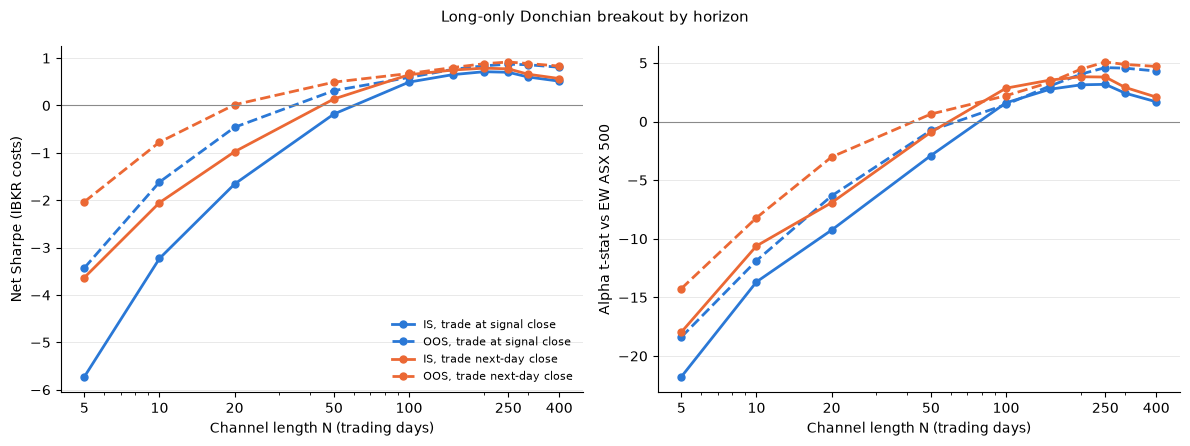

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
styles = {(1, "IS"): (BLUE, "-"), (1, "OOS"): (BLUE, "--"), (2, "IS"): (ORANGE, "-"), (2, "OOS"): (ORANGE, "--")}
for ax, (col, label) in zip(axs, [("sharpe", "Net Sharpe (IBKR costs)"), ("alpha_t", "Alpha t-stat vs EW ASX 500")]):
    for (lag, per), (c, ls) in styles.items():
        g = horizon.xs((lag, per), level=("lag", "period"))[col]
        ax.plot(g.index, g.values, color=c, ls=ls, marker="o", ms=5, lw=2,
                label=f"{per}, trade {'at signal' if lag == 1 else 'next-day'} close")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xscale("log")
    ax.set_xticks([5, 10, 20, 50, 100, 250, 400], labels=[5, 10, 20, 50, 100, 250, 400])
    ax.set_xlabel("Channel length N (trading days)")
    ax.set_ylabel(label)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
axs[0].legend(fontsize=8, frameon=False)
fig.suptitle("Long-only Donchian breakout by horizon", fontsize=11)
fig.tight_layout()
fig.savefig(RESULTS / "horizon_sweep.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading the sweep**
* **N ≤ 20 days: reversal.** Short-horizon breakouts lose heavily to the benchmark (alpha t-stats of −7 to −18 at the next close). Part of this is bid-ask bounce (a breakout close is often an ask-side print that reverses the next day) and part is cost: short channels trade constantly and pay the spread each time.
* **N ≥ 100 days: momentum.** Alpha against the equal-weight ASX 500 is significant from 100 days up, with a broad plateau between 150 and 250 days in-sample (t ≈ 3.5–3.8) that holds out-of-sample (t ≈ 3.3–5.1). The plateau means the choice is not knife-edge.
* **Execution matters.** Trading one day later (`lag=2`) beats trading at the breakout close at every horizon. Don't chase the breakout print.

## 5. Exit channel (IS only)

In [9]:
exit_grid = {}
for n in [150, 200, 250, 300]:
    for ratio in [0.25, 0.5, 1.0]:
        m = int(n * ratio)
        exit_grid[(n, m)] = stats(backtest_drift(donchian_long(df, n, m), df)["net"].loc[IS], ew)
exit_grid = pd.DataFrame(exit_grid).T.rename_axis(["N", "M"])
exit_grid.to_csv(RESULTS / "03_exit_grid_IS.csv")
N, M = exit_grid["sharpe"].idxmax()
print(f"best IS Sharpe: N={N}, M={M}")
exit_grid[["sharpe", "alpha_t"]].round(2)

best IS Sharpe: N=200, M=50


sharpe  alpha_t
N   M                   
150 37    0.800    3.110
    75    0.750    3.540
    150   0.550    2.260
200 50    0.950    4.440
    100   0.790    3.820
    200   0.580    2.690
250 62    0.930    4.370
    125   0.770    3.800
    250   0.600    3.090
300 75    0.910    4.240
    150   0.660    2.910
    300   0.560    2.820

**N=200, M=50** has the best in-sample Sharpe (0.95) and the best alpha t-stat (4.4). The tight exit (M = N/4) is best at every entry length: a long-only book is better off cutting a failed breakout early. The spec is fixed from here on.

## 6. Activity: are high-volume breakouts stronger?

The brief suggests that moves with heavy activity and new information carry more momentum. Entries are split by breakout-day volume relative to its 50-day average.

In [10]:
vol_bts = {f"volume = {vf or 'any'}": backtest_drift(donchian_long(df, N, M, vol_filter=vf), df) for vf in [None, "high", "low"]}
vol_table = report(vol_bts, ew)
vol_table.to_csv(RESULTS / "04_volume_filter.csv")
vol_table[["sharpe", "alpha", "alpha_t"]].unstack("period").round(3)

sharpe       alpha       alpha_t      
period            IS   OOS    IS   OOS      IS   OOS
strategy                                            
volume = any   0.947 0.819 0.127 0.078   4.443 3.213
volume = high  0.920 0.888 0.135 0.095   4.327 3.636
volume = low   0.999 0.803 0.125 0.071   4.195 2.642

Volume confirmation adds nothing in-sample (Sharpe 0.95 for all breakouts, 0.92 for high-volume, 1.00 for low-volume), so the filter is not used.

## 7. Final strategy

In [11]:
s = donchian_long(df, N, M)
bt_final, hold = backtest_drift(s, df, holdings=True)
strat = bt_final["net"]

periods = PERIODS + (("FULL", slice("2006-01-01", None)),)
final = report({"Breakout long-only": bt_final}, ew, periods)
vs_aord = pd.DataFrame({("Breakout long-only", per): stats(strat.loc[sl], axjo)[["alpha", "alpha_t", "beta"]]
                        for per, sl in periods}).T.add_suffix("_aord").rename_axis(final.index.names)
bench_rows = pd.DataFrame({(name, per): stats(r.loc[sl]) for name, r in [("Benchmark: EW ASX 500", ew), ("Benchmark: All Ords", axjo)]
                           for per, sl in periods}).T
final = pd.concat([final.join(vs_aord), bench_rows]).rename_axis(["strategy", "period"])
final.to_csv(RESULTS / "05_final_strategies.csv")
final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta", "info_ratio", "alpha_aord", "beta_aord", "turnover"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  beta  info_ratio  alpha_aord  beta_aord  turnover
strategy              period                                                                                                     
Breakout long-only    IS        0.174    0.184   0.947  -0.486  0.127    4.443 0.872       1.272       0.150      0.723     0.031
                      OOS       0.157    0.192   0.819  -0.431  0.078    3.213 0.864       0.795       0.106      0.924     0.029
                      FULL      0.166    0.188   0.885  -0.486  0.104    5.463 0.868       1.062       0.132      0.800     0.030
Benchmark: EW ASX 500 IS        0.054    0.183   0.296  -0.680    NaN      NaN   NaN         NaN         NaN        NaN       NaN
                      OOS       0.092    0.203   0.453  -0.453    NaN      NaN   NaN         NaN         NaN        NaN       NaN
                      FULL      0.072    0.193   0.374  -0.680    NaN      NaN   NaN         NaN         NaN        NaN       NaN
Benchmark: All Ords   IS        0.033    0.175   0.188  -0.546    NaN      NaN   NaN         NaN         NaN        NaN       NaN
                      OOS       0.055    0.146   0.375  -0.371    NaN      NaN   NaN         NaN         NaN        NaN       NaN
                      FULL      0.043    0.162   0.267  -0.546    NaN      NaN   NaN         NaN         NaN        NaN       NaN

`alpha`, `beta` and `info_ratio` are measured against the equal-weight ASX 500; the `_aord` columns are against the All Ordinaries. Alpha is annualised, with Newey-West (10-lag) t-stats. Returns are net of IBKR commission and half-spread.

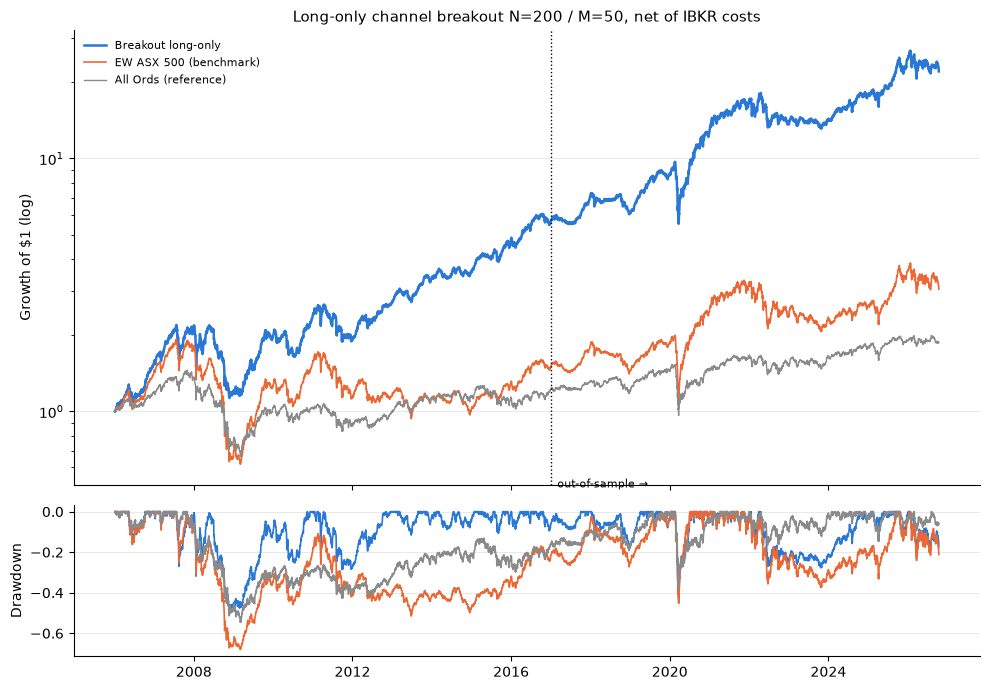

In [12]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for name, r, c, lw in [("Breakout long-only", strat, BLUE, 1.8), ("EW ASX 500 (benchmark)", ew, ORANGE, 1.2),
                       ("All Ords (reference)", axjo.fillna(0), GREY, 1.0)]:
    eq = (1 + r.loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=lw, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
axs[0].axvline(pd.Timestamp("2017-01-01"), color="k", ls=":", lw=1)
axs[0].text(pd.Timestamp("2017-03-01"), 0.5, "out-of-sample →", fontsize=8)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title(f"Long-only channel breakout N={N} / M={M}, net of IBKR costs", fontsize=11)
axs[0].legend(fontsize=8, frameon=False)
axs[1].set_ylabel("Drawdown")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "equity_curves.png", dpi=130)
plt.show()

* **Return and risk.** After IBKR costs the book earns 17.4% a year in-sample and 15.7% out-of-sample, with a Sharpe of 0.95 and 0.82. The equal-weight ASX 500 earns 5.4% and 9.2% (Sharpe 0.30 and 0.45).
* **Alpha.** 12.7% a year in-sample (t = 4.4) and 7.8% out-of-sample (t = 3.2) against the equal-weight ASX 500; larger against the All Ords.
* **Drawdown.** −49% in-sample and −43% out-of-sample. That is less than the equal-weight benchmark in 2008 (−68%) but still an equity-sized loss: the book is fully invested, with a beta of 0.7–0.9.

## 8. Execution and costs

**Cost models.** The headline is IBKR's 0.08% commission plus half a one-tick spread. The table compares it with no costs, commission only, twice the spread (a stress for thin names), and the flat 20 bps the project brief assumed.

**IBKR's A$6 minimum per order.** 0.08% only exceeds A$6 on orders above A$7,500. The engine trims every held name a little each time a new breakout enters, so it sends over 100 small orders a day, and on a small account each one would pay the minimum. The second table applies the minimum for three account sizes.

**Execution timing.** The last rows trade at the signal close instead of the next close.

In [13]:
COST_MODELS = {"no costs": dict(commission_bps=0, spread=0),
               "IBKR commission only (0.08%)": dict(spread=0),
               "IBKR commission + half-spread (headline)": dict(),
               "IBKR commission + 2 x half-spread": dict(spread=2.0),
               "flat 20 bps (project brief)": dict(commission_bps=20, spread=0),
               "headline costs, trade at signal close": dict(lag=1),
               "no costs, trade at signal close": dict(commission_bps=0, spread=0, lag=1)}
cost_bts = {name: backtest_drift(s, df, **kw) for name, kw in COST_MODELS.items()}
costs = report(cost_bts, ew)
costs.to_csv(RESULTS / "06_costs.csv")
display(costs[["cost_pa", "ann_ret", "sharpe", "alpha", "alpha_t"]].unstack("period").reindex(list(cost_bts)).round(3))

min_bts = {f"A${c / 1e6:,.0f}m account": backtest_drift(s, df, capital=c) for c in [1e6, 10e6, 100e6]}
min_fee = report(min_bts, ew)
min_fee.to_csv(RESULTS / "06b_minimum_fee.csv")
print(f"orders a day: {bt_final['orders'].loc['2006':].mean():.0f};  "
      f"median half-spread of held names: {1e4 * HALF_SPREAD.where(hold > 0).loc['2006':].median(axis=1).median():.0f} bps")
min_fee[["cost_pa", "ann_ret", "sharpe", "alpha", "alpha_t"]].unstack("period").reindex(list(min_bts)).round(3)

cost_pa       ann_ret       sharpe       alpha       alpha_t      
period                                        IS   OOS      IS   OOS     IS   OOS    IS   OOS      IS   OOS
strategy                                                                                                   
no costs                                   0.000 0.000   0.202 0.185  1.100 0.966 0.155 0.106   5.465 4.413
IBKR commission only (0.08%)               0.006 0.006   0.196 0.179  1.066 0.935 0.149 0.100   5.243 4.160
IBKR commission + half-spread (headline)   0.028 0.028   0.174 0.157  0.947 0.819 0.127 0.078   4.443 3.213
IBKR commission + 2 x half-spread          0.050 0.050   0.152 0.135  0.827 0.703 0.105 0.055   3.646 2.274
flat 20 bps (project brief)                0.015 0.015   0.187 0.171  1.016 0.889 0.140 0.091   4.910 3.781
headline costs, trade at signal close      0.029 0.029   0.150 0.147  0.820 0.761 0.103 0.067   3.403 2.733
no costs, trade at signal close            0.000 0.000   0.179 0.175  0.978 0.914 0.132 0.096   4.385 3.960

orders a day: 115;  median half-spread of held names: 15 bps


cost_pa       ann_ret        sharpe         alpha        alpha_t       
period              IS   OOS      IS    OOS     IS    OOS     IS    OOS      IS    OOS
strategy                                                                              
A$1m account     0.173 0.225   0.030 -0.039  0.161 -0.204 -0.018 -0.119  -0.601 -4.841
A$10m account    0.041 0.046   0.162  0.140  0.878  0.727  0.114  0.060   3.996  2.487
A$100m account   0.029 0.029   0.174  0.156  0.944  0.815  0.126  0.077   4.426  3.182

* **The spread costs more than the commission.** IBKR's 0.08% commission takes 0.6% a year. Half a one-tick spread takes another 2.2%, because the median held name has a half-spread of 15 bps. Together they cost 2.8% a year, nearly twice the flat 20 bps the brief assumed (1.5%).
* **The edge survives.** With the headline costs the out-of-sample alpha is 7.8% (t = 3.2). With twice the spread it is still 5.5% (t = 2.3).
* **The A$6 minimum decides the account size.** The engine sends about 115 orders a day, most of them small trims of existing holdings. On a **A$1m account** nearly every order pays the minimum: costs reach 17–22% of capital a year and the strategy loses money. At **A$10m** costs are 4–5% a year and the alpha holds (11.4% in-sample, 6.0% out-of-sample, t = 2.5). At **A$100m** the minimum is irrelevant.
* A small account would have to trade differently: fund new entries from cash and trim the existing names in one batch every week or month, not daily. That variant is not tested here.
* **Timing.** Trading at the signal close is worse than waiting a day, with or without costs.

## 9. Calendar years

In [14]:
yearly = pd.DataFrame({"Breakout long-only": strat, "EW ASX 500": ew, "All Ords": axjo}).loc["2006":].fillna(0)
yearly = yearly.groupby(yearly.index.year).apply(lambda x: (1 + x).prod() - 1)
yearly["active vs EW ASX 500"] = yearly["Breakout long-only"] - yearly["EW ASX 500"]
yearly.to_csv(RESULTS / "07_yearly.csv")
full = yearly.loc[:2025]
print(f"full years ahead of the EW ASX 500: {(full['active vs EW ASX 500'] > 0).sum()} of {len(full)};  "
      f"positive full years: {(full['Breakout long-only'] > 0).sum()} of {len(full)}")
yearly.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4)

full years ahead of the EW ASX 500: 18 of 20;  positive full years: 16 of 20


,Breakout long-only,EW ASX 500,All Ords,active vs EW ASX 500
date,,,,
2006,55.9%,43.4%,19.9%,12.6%
2007,38.0%,25.8%,13.8%,12.1%
2008,-44.0%,-61.8%,-43.0%,17.9%
2009,65.0%,84.9%,33.4%,-19.9%
2010,20.6%,23.0%,-0.7%,-2.5%
2011,-20.4%,-28.0%,-15.2%,7.5%
2012,40.8%,2.0%,13.5%,38.8%
2013,25.5%,-1.9%,14.8%,27.5%
2014,4.9%,-10.0%,0.7%,14.8%


* The book beat the equal-weight ASX 500 in **18 of 20 full years**. The exceptions are 2009 and 2010: after the crash the most beaten-down stocks rebounded hardest, and a breakout book does not hold them.
* It made money in 16 of 20 years. The losing years are the market's: 2008 (−44%), 2011, 2018 and 2022. The exit rule softens a crash (the benchmark lost 62% in 2008) but does not avoid it.

## 10. Size control

The book holds every breakout at an equal weight, so it holds many smaller companies; some of its alpha could be a size tilt. A second factor is added: EW ASX 500 minus EW top 200 (by traded value), both drifting. The table also shows how many names the book holds.

In [15]:
rank = df["adv"].where(df["member"]).rank(axis=1, ascending=False)
top200 = (rank <= 200).shift(1, fill_value=False)
ew200 = backtest_drift((df["member"] & top200).astype(float), df, commission_bps=0, spread=0, lag=1)["net"]
factors = pd.DataFrame({"ew_asx500": ew, "size": ew - ew200})
H = hold.loc["2006":]
rows = {}
for per, sl in PERIODS:
    fit = sm.OLS(strat.loc[sl], sm.add_constant(factors.loc[sl].fillna(0))).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    rows[per] = {"alpha": fit.params["const"] * TRADING_DAYS, "alpha_t": fit.tvalues["const"],
                 "beta_ew": fit.params["ew_asx500"], "beta_size": fit.params["size"],
                 "names held": (H.loc[sl] > 0).sum(axis=1).mean(),
                 "share of longs in top 200": ((H.loc[sl] > 0) & top200.loc[H.loc[sl].index]).sum(axis=1).sum() / (H.loc[sl] > 0).sum(axis=1).sum(),
                 "weight in top 10 names": np.sort(H.loc[sl].values, axis=1)[:, -10:].sum(axis=1).mean()}
size_ctrl = pd.DataFrame(rows).T
size_ctrl.to_csv(RESULTS / "09_size_control.csv")
size_ctrl

,alpha,alpha_t,beta_ew,beta_size,names held,share of longs in top 200,weight in top 10 names
IS,0.120,4.267,0.860,-0.275,118.595,0.625,0.219
OOS,0.078,3.231,0.862,0.028,148.237,0.483,0.149


The alpha is not a size tilt. Adding the size factor leaves it at 12.0% in-sample (t = 4.3) and 7.8% out-of-sample (t = 3.2), and the size beta is small (−0.28 and 0.03). The book holds about 120–150 names with 15–22% of capital in the ten largest positions, and roughly half of its longs are among the 200 most liquid stocks.

## 11. Liquidity / capacity

In [16]:
held_adv = (df["adv"].where(hold > 0).median(axis=1) / 1e6).loc["2006":]
liq = held_adv.groupby(held_adv.index.year).median().rename("median traded value of held names, A$m/day")
liq.to_csv(RESULTS / "08_liquidity.csv")
liq.to_frame().T.round(2)

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"median traded value of held names, A$m/day",0.140,0.200,0.360,0.100,0.170,0.190,0.350,0.470,0.270,0.230,...,0.290,0.390,0.720,0.570,1.290,2.610,2.110,1.480,1.600,3.400


The median held stock traded well under A$1m a day before 2021. That pulls against the minimum-fee result in section 8: the A$6 minimum calls for an account of A$10m or more, but A$10m spread over about 130 names is A$75,000 a position, a large share of a day's trading in the thinnest names. The realistic choices are a smaller account that batches its trims, or a liquidity cap on what the book may hold.

## 12. Monte Carlo: strategy vs random buy-and-hold

**Question:** is the strategy better than just buying a random basket of ASX 500 stocks and holding it?

**Setup**
* Each simulation picks **K** stocks at random from the ASX 500 members on the start date, buys them equal weight (paying commission and half-spread once), and holds them to the end with no rebalancing.
* 1,000 simulations for each K: K=30 (a typical concentrated investor) and K = the strategy's average number of longs.
* Two windows: full sample (2006–) and OOS (2017–).
* Random picks come from stocks still listed today, the **same survivorship bias** as the strategy.

**Control.** The same random picks are also reset to equal weight **every day**, with no costs. This is the construction the first backtest effectively used. It is not investable, and it measures how much daily resetting on closing prices inflates results.

In [17]:
def metrics(r, bench):
    # vectorised annual metrics for a days x portfolios matrix
    r = np.asarray(r)
    r = r[:, None] if r.ndim == 1 else r
    eq = np.cumprod(1 + r, axis=0)
    b = np.asarray(bench)
    bc = b - b.mean()
    beta = (bc[:, None] * (r - r.mean(0))).sum(0) / (bc ** 2).sum()
    vol = r.std(0, ddof=1) * np.sqrt(TRADING_DAYS)
    return pd.DataFrame({
        "cagr": eq[-1] ** (TRADING_DAYS / len(r)) - 1,
        "ann_vol": vol,
        "sharpe": r.mean(0) * TRADING_DAYS / vol,
        "max_dd": (eq / np.maximum.accumulate(eq, axis=0) - 1).min(0),
        "alpha_aord": (r.mean(0) - beta * b.mean()) * TRADING_DAYS,
        "beta_aord": beta,
    })


def random_baskets(start, k, n_sims, rng):
    # n_sims x stocks equal start weights on K random members
    pool = np.flatnonzero(df["member"].loc[start:].iloc[0].values)
    w0 = np.zeros((n_sims, df["member"].shape[1]))
    for i in range(n_sims):
        w0[i, rng.choice(pool, size=k, replace=False)] = 1 / k
    return w0


def buy_and_hold(growth, w0, cost=0.0):
    # days x sims value of $1 bought at start weights w0 and never traded, and its daily returns
    value = growth @ w0.T * (1 - cost)
    return value, np.vstack([value[:1] - 1, value[1:] / value[:-1] - 1])


N_SIMS, COST = 1000, 23e-4          # one purchase: 8 bps commission + a typical 15 bps half-spread
WINDOWS = {"FULL 2006-": "2006-01-03", "OOS 2017-": "2017-01-03"}
k_match = int(round((s > 0).sum(axis=1).loc["2006":].mean()))
ret0, axjo0 = df["ret"].fillna(0.0), axjo.fillna(0.0)
rng = np.random.default_rng(7)

rows, dists, fans = [], {}, {}
for wname, start in WINDOWS.items():
    r_win, b_win = ret0.loc[start:], axjo0.loc[start:]
    growth = np.cumprod(1 + r_win.values, axis=0)
    for k in [30, k_match]:
        w0 = random_baskets(start, k, N_SIMS, rng)
        value, daily = buy_and_hold(growth, w0, COST)
        dists[(wname, k)], fans[(wname, k)] = metrics(daily, b_win), value
        reset = metrics(r_win.values @ w0.T, b_win)                  # control: daily reset to equal weight
        for label, m in [(f"random B&H, K={k}", dists[(wname, k)]), (f"control: daily-reset EW, K={k}", reset)]:
            for q, row in m.quantile([0.05, 0.5, 0.95]).iterrows():
                rows.append({"window": wname, "portfolio": label, "stat": f"p{int(q * 100)}", **row})
    ms = metrics(strat.loc[start:].values, b_win).iloc[0]
    rows.append({"window": wname, "portfolio": "Breakout long-only", "stat": "value", **ms})
    for k in [30, k_match]:
        rows.append({"window": wname, "portfolio": "Breakout long-only", "stat": f"percentile vs K={k}",
                     **{c: (dists[(wname, k)][c] < ms[c]).mean() * 100 for c in ["cagr", "sharpe", "max_dd", "alpha_aord"]}})

mc = pd.DataFrame(rows)
mc.to_csv(RESULTS / "10_mc_buyhold.csv", index=False)
print(f"K matched to the strategy's average long count: {k_match}")
mc[mc["window"] == "OOS 2017-"].drop(columns="window").set_index(["portfolio", "stat"])

K matched to the strategy's average long count: 133


cagr  ann_vol  sharpe  max_dd  alpha_aord  beta_aord
portfolio                      stat                                                                       
random B&H, K=30               p5                    0.024    0.172   0.222  -0.588      -0.003      0.773
                               p50                   0.081    0.210   0.470  -0.472       0.050      0.937
                               p95                   0.140    0.267   0.721  -0.385       0.104      1.086
control: daily-reset EW, K=30  p5                    0.155    0.167   0.898  -0.484       0.117      0.648
                               p50                   0.223    0.190   1.161  -0.428       0.178      0.752
                               p95                   0.308    0.214   1.415  -0.365       0.250      0.862
random B&H, K=133              p5                    0.058    0.162   0.416  -0.470       0.021      0.887
                               p50                   0.085    0.177   0.545  -0.438       0.045      0.951
                               p95                   0.108    0.195   0.665  -0.403       0.066      1.022
control: daily-reset EW, K=133 p5                    0.202    0.140   1.339  -0.441       0.153      0.703
                               p50                   0.233    0.147   1.504  -0.417       0.179      0.752
                               p95                   0.267    0.154   1.673  -0.392       0.207      0.801
Breakout long-only             value                 0.149    0.192   0.819  -0.431       0.106      0.924
                               percentile vs K=30   96.700      NaN  99.100  76.800      95.700        NaN
                               percentile vs K=133 100.000      NaN 100.000  63.400     100.000        NaN

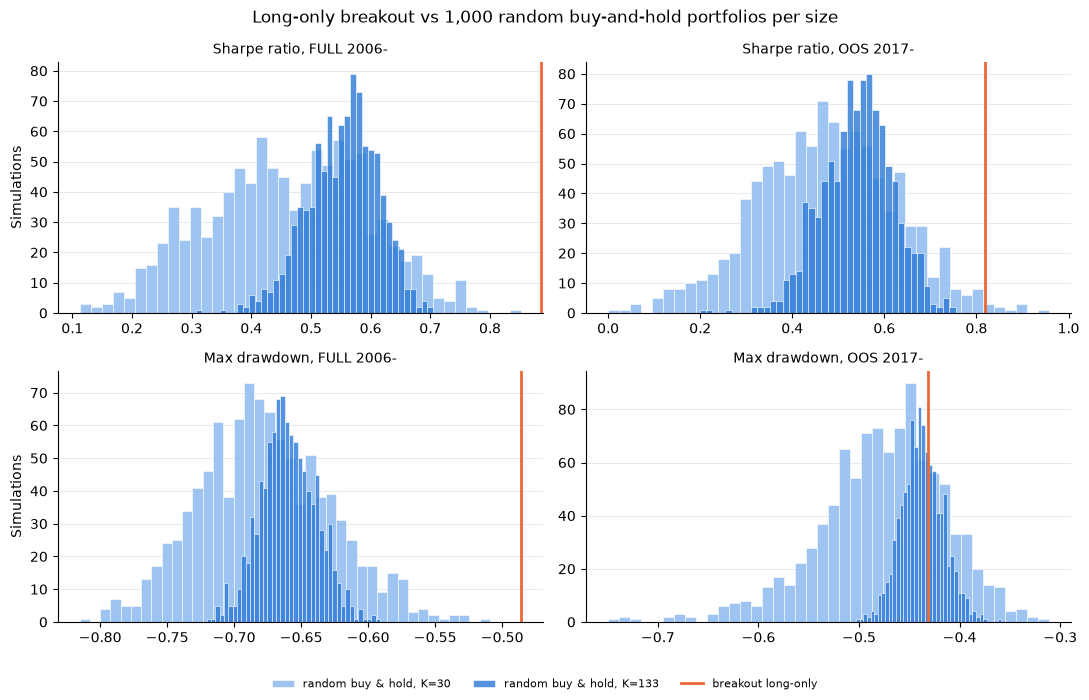

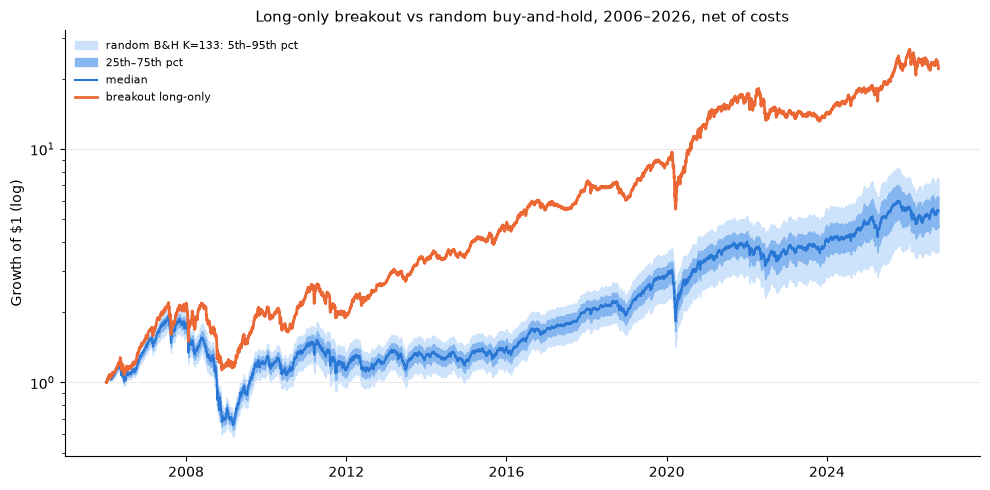

In [18]:
fig, axs = plt.subplots(2, 2, figsize=(11, 7))
for i, wname in enumerate(WINDOWS):
    for j, (col, label) in enumerate([("sharpe", "Sharpe ratio"), ("max_dd", "Max drawdown")]):
        ax = axs[j, i]
        for k, c in [(30, BLUE_MID), (k_match, BLUE)]:
            ax.hist(dists[(wname, k)][col], bins=40, color=c, alpha=0.8, edgecolor="white", linewidth=0.5,
                    label=f"random buy & hold, K={k}")
        ax.axvline(metrics(strat.loc[WINDOWS[wname]:].values, axjo0.loc[WINDOWS[wname]:]).iloc[0][col],
                   color=ORANGE, lw=2, label="breakout long-only")
        ax.set_title(f"{label}, {wname}", fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e5e5e5", lw=0.6)
        ax.set_axisbelow(True)
axs[0, 0].set_ylabel("Simulations")
axs[1, 0].set_ylabel("Simulations")
handles, labels = axs[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, frameon=False)
fig.suptitle(f"Long-only breakout vs {N_SIMS:,} random buy-and-hold portfolios per size", fontsize=12)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(RESULTS / "mc_distributions.png", dpi=130)
plt.show()

value = fans[("FULL 2006-", k_match)]
idx = ret0.loc[WINDOWS["FULL 2006-"]:].index
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(idx, np.percentile(value, 5, axis=1), np.percentile(value, 95, axis=1), color=BLUE_LIGHT,
                label=f"random B&H K={k_match}: 5th–95th pct")
ax.fill_between(idx, np.percentile(value, 25, axis=1), np.percentile(value, 75, axis=1), color=BLUE_MID, label="25th–75th pct")
ax.plot(idx, np.median(value, axis=1), color=BLUE, lw=1.5, label="median")
ax.plot(idx, (1 + strat.loc[WINDOWS["FULL 2006-"]:]).cumprod(), color=ORANGE, lw=2, label="breakout long-only")
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log)")
ax.set_title("Long-only breakout vs random buy-and-hold, 2006–2026, net of costs", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(RESULTS / "mc_equity_fan.png", dpi=130)
plt.show()

**Reading the Monte Carlo (out-of-sample table)**
* The breakout book beats every random basket of the same size on return, Sharpe and alpha, in both windows.
* Its drawdown is mid-pack: it is a better stock picker, not a safer one.
* **Control:** random stocks reset to equal weight daily show a CAGR above 20% and a Sharpe near 1.5 with no skill at all. That is the size of the daily-reset artifact, and the reason this research uses drifting holdings.

## 13. Is the edge statistically significant?

"Different from random buy-and-hold" can mean two things, and each needs its own test:

* **Luck in which stocks were picked.** Every random portfolio lives through the same 2006–2026 market, so beating them shows the strategy beat random *selection* in this history (tests 13a, 13b).
* **Luck in the history itself.** Would the edge survive if the same market had played out in a different order? This needs resampling of time (test 13c).

Finally, about 35 configurations were tried in-sample, so the chosen one is the best of many noisy results (test 13d).

### 13a. Monte Carlo empirical p-values

From section 12, with K matched to the strategy. The p-value is the share of random portfolios that did at least as well: $p = \dfrac{1 + \#\{\text{random} \ge \text{strategy}\}}{1 + N}$.

In [19]:
rows = {}
for wname, start in WINDOWS.items():
    ms = metrics(strat.loc[start:].values, axjo0.loc[start:]).iloc[0]
    dist = dists[(wname, k_match)]
    rows[wname] = {f"p_{c}": (1 + (dist[c] >= ms[c]).sum()) / (1 + len(dist)) for c in ["cagr", "sharpe", "alpha_aord"]}
mc_p = pd.DataFrame(rows).T
mc_p.to_csv(RESULTS / "11a_mc_pvalues.csv")
mc_p.style.format("{:.3f}")

,p_cagr,p_sharpe,p_alpha_aord
FULL 2006-,0.001,0.001,0.001
OOS 2017-,0.001,0.001,0.001


The book beats all 1,000 random baskets on return, Sharpe and alpha in both windows (p ≈ 0.001, the floor for 1,000 simulations).

### 13b. Signal-shift permutation test (does breakout *timing* matter?)

Random buy-and-hold holds the same names throughout; the strategy moves in and out. A stricter null keeps the strategy's exact structure and randomises only the **timing**.

* Each stock's signal series is shifted forward by a random number of days (at least a year), wrapping around the end.
* This keeps each stock's number of trades and holding periods, but breaks the link between the signal and real breakouts.
* Shifted signals are re-masked to the universe, then backtested with the same engine and costs.

200 permutations give a p-value floor of 1/201 ≈ 0.005. (This cell takes a few minutes.)

In [20]:
N_PERM = 200
prng = np.random.default_rng(5)
mem = df["member"].values
sv0 = s.values
null = []
for _ in range(N_PERM):
    sv = np.empty_like(sv0)
    for j in range(sv0.shape[1]):
        sv[:, j] = np.roll(sv0[:, j], prng.integers(252, len(sv0) - 252))
    sp = pd.DataFrame(np.where(mem, sv, 0.0), s.index, s.columns)
    null.append(stats(backtest_drift(sp, df)["net"].loc["2006":])["sharpe"])
null = np.array(null)
obs = stats(strat.loc["2006":])["sharpe"]
perm_table = pd.DataFrame({"Breakout long-only": {
    "observed Sharpe": obs, "null p5": np.percentile(null, 5), "null median": np.median(null),
    "null p95": np.percentile(null, 95), "p-value": (1 + (null >= obs).sum()) / (1 + N_PERM)}}).T
perm_table.to_csv(RESULTS / "11b_permutation.csv")
perm_table

,observed Sharpe,null p5,null median,null p95,p-value
Breakout long-only,0.885,0.427,0.545,0.668,0.005


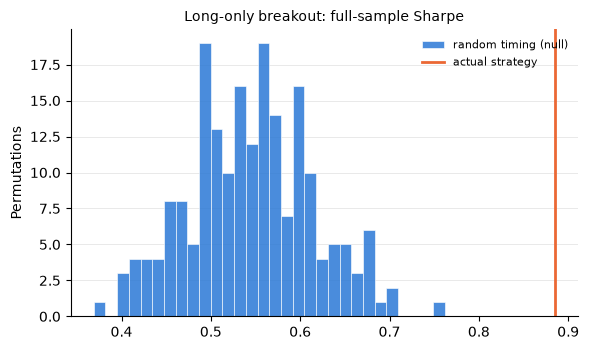

In [21]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.hist(null, bins=30, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.5, label="random timing (null)")
ax.axvline(obs, color=ORANGE, lw=2, label="actual strategy")
ax.set_title("Long-only breakout: full-sample Sharpe", fontsize=10)
ax.set_ylabel("Permutations")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.set_axisbelow(True)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "permutation_test.png", dpi=130)
plt.show()

The book beats all 200 timing-shuffled versions (p ≈ 0.005, the floor). Its Sharpe is 0.89 against a null median of 0.55. The null is well above zero because any long book of these stocks earns the equity premium, but breakout timing adds a clear margin on top.

### 13c. Paired stationary block bootstrap (does the edge survive a different history?)

* Resample the 2006–2026 (or 2017–2026) daily history in **blocks** of random length (mean 20 days; the stationary bootstrap of Politis & Romano). Blocks keep volatility clustering and autocorrelation intact.
* The resample is **paired**: the same days are drawn for the strategy and the benchmark, so their common exposure to the market is preserved.
* In each of 2,000 resamples, compute the difference in Sharpe (or mean return) between the strategy and (i) the drifting equal-weight ASX 500, and (ii) the median of 200 random buy-and-hold portfolios (K matched) evaluated on the same resampled days.
* The 95% interval is the 2.5th–97.5th percentile of those differences. The two-sided p-value is twice the share of resamples on the wrong side of zero.

This is the Ledoit & Wolf (2008) approach to testing Sharpe-ratio differences.

In [22]:
def stationary_bootstrap_idx(T, B, mean_block, rng):
    idx = np.empty((B, T), dtype=np.int64)
    idx[:, 0] = rng.integers(0, T, B)
    jump = rng.random((B, T)) < 1 / mean_block
    fresh = rng.integers(0, T, (B, T))
    for t in range(1, T):
        idx[:, t] = np.where(jump[:, t], fresh[:, t], (idx[:, t - 1] + 1) % T)
    return idx


def ann_sharpe(x, axis=0):
    return x.mean(axis) / x.std(axis) * np.sqrt(TRADING_DAYS)


B, BLOCK, N_RAND = 2000, 20, 200
brng = np.random.default_rng(11)
TESTS = ("ΔSharpe vs EW ASX 500", "ΔSharpe vs median random B&H", "Δann. return vs median random B&H")
boot_rows = {}
for wname, start in WINDOWS.items():
    r_win = ret0.loc[start:]
    growth = np.cumprod(1 + r_win.values, axis=0)
    rand = buy_and_hold(growth, random_baskets(start, k_match, N_RAND, brng))[1]     # T x N_RAND random B&H daily returns
    e, x = ew.loc[start:].values, strat.loc[start:].values
    diffs = {t: [] for t in TESTS}
    for row in stationary_bootstrap_idx(len(r_win), B, BLOCK, brng):
        xs, rs = x[row], rand[row]
        sx = ann_sharpe(xs)
        diffs[TESTS[0]].append(sx - ann_sharpe(e[row]))
        diffs[TESTS[1]].append(sx - np.median(ann_sharpe(rs)))
        diffs[TESTS[2]].append((xs.mean() - np.median(rs.mean(0))) * TRADING_DAYS)
    observed = {TESTS[0]: ann_sharpe(x) - ann_sharpe(e), TESTS[1]: ann_sharpe(x) - np.median(ann_sharpe(rand)),
                TESTS[2]: (x.mean() - np.median(rand.mean(0))) * TRADING_DAYS}
    for test, arr in diffs.items():
        arr = np.array(arr)
        boot_rows[(wname, test)] = {"observed": observed[test], "ci_low": np.percentile(arr, 2.5), "ci_high": np.percentile(arr, 97.5),
                                    "p_value": max(2 * min((arr <= 0).mean(), (arr >= 0).mean()), 1 / B)}
boot = pd.DataFrame(boot_rows).T
boot.to_csv(RESULTS / "11c_block_bootstrap.csv")
boot

observed  ci_low  ci_high  p_value
FULL 2006- ΔSharpe vs EW ASX 500                 0.511   0.300    0.734    0.001
           ΔSharpe vs median random B&H          0.327   0.060    0.586    0.019
           Δann. return vs median random B&H     0.071   0.024    0.116    0.002
OOS 2017-  ΔSharpe vs EW ASX 500                 0.366   0.123    0.633    0.001
           ΔSharpe vs median random B&H          0.259  -0.028    0.574    0.081
           Δann. return vs median random B&H     0.058   0.003    0.118    0.043

**Reading the bootstrap**
* **Against the equal-weight ASX 500** the higher Sharpe is significant in both windows (p = 0.001).
* **Against the median random basket** the higher *return* is significant in both windows. The higher *Sharpe* is significant over the full sample (p = 0.02) but not quite out-of-sample (p = 0.08): ten years is a short time to tell two Sharpe ratios apart.

### 13d. Deflated Sharpe ratio (correcting for the search)

The spec was chosen as the best of about 35 in-sample trials (sections 4–6). Even with no real edge, the best of many noisy results would look good. The **deflated Sharpe ratio** (Bailey & López de Prado, 2014) raises the hurdle to the Sharpe you would *expect* from the best of N worthless trials, then asks how likely the observed Sharpe is to beat it, adjusting for skew and fat tails.

$$SR_0 = \sqrt{V[\widehat{SR}_n]}\left[(1-\gamma)\,\Phi^{-1}\!\left(1-\tfrac{1}{N}\right) + \gamma\,\Phi^{-1}\!\left(1-\tfrac{1}{Ne}\right)\right],\qquad
DSR = \Phi\!\left(\frac{(\widehat{SR}-SR_0)\sqrt{T-1}}{\sqrt{1-\hat\gamma_3\widehat{SR}+\tfrac{\hat\gamma_4-1}{4}\widehat{SR}^2}}\right)$$

$V$ is the variance of the trial Sharpe ratios, γ ≈ 0.5772 (the Euler–Mascheroni constant), and $\hat\gamma_3, \hat\gamma_4$ are the skew and kurtosis of daily returns. A DSR above 0.95 means significant at 5% after correcting for the search.

A long-only book has a positive Sharpe just from holding equities, so the test is run on the **active return** (strategy minus the equal-weight ASX 500), whose Sharpe is the information ratio. The out-of-sample period involved no search, so there the plain **probabilistic Sharpe ratio** (PSR, with hurdle $SR_0 = 0$) is the right test.

In [23]:
from scipy.stats import kurtosis, norm, skew


def psr(r, sr0_daily=0.0):
    r = r.dropna()
    sr = r.mean() / r.std()
    g3, g4 = skew(r), kurtosis(r, fisher=False)
    z = (sr - sr0_daily) * np.sqrt(len(r) - 1) / np.sqrt(1 - g3 * sr + (g4 - 1) / 4 * sr ** 2)
    return norm.cdf(z)


def sr0_hurdle(trial_sharpes_ann, n_trials):
    v = np.var(np.asarray(trial_sharpes_ann) / np.sqrt(TRADING_DAYS), ddof=1)
    em = 0.5772156649
    return np.sqrt(v) * ((1 - em) * norm.ppf(1 - 1 / n_trials) + em * norm.ppf(1 - 1 / (n_trials * np.e)))


trials = np.r_[horizon.xs("IS", level="period")["info_ratio"].values, exit_grid["info_ratio"].values,
               vol_table.xs("IS", level="period")["info_ratio"].values]
active = strat - ew
dsr_rows = {}
for label, tr in [(f"all {len(trials)} trials", trials), ("plausible trials only (IR > -0.6)", trials[trials > -0.6])]:
    h = sr0_hurdle(tr, len(trials))
    dsr_rows[f"IS selection, {label}"] = {"info ratio": ann_sharpe(active.loc[IS]), "hurdle": h * np.sqrt(TRADING_DAYS),
                                          "probability": psr(active.loc[IS], h)}
dsr_rows["OOS PSR, active return"] = {"info ratio": ann_sharpe(active.loc[OOS]), "hurdle": 0.0, "probability": psr(active.loc[OOS])}
dsr = pd.DataFrame(dsr_rows).T
dsr.to_csv(RESULTS / "11d_deflated_sharpe.csv")
dsr

,info ratio,hurdle,probability
"IS selection, all 35 trials",1.272,5.761,0.000
"IS selection, plausible trials only (IR > -0.6)",1.272,0.719,0.966
"OOS PSR, active return",0.795,0.000,0.993


**Reading the deflated Sharpe**
* **With all 35 trials the hurdle is far too high** (information ratio ≈ 5.8). The formula treats the spread of trial results as noise, but most of the spread here is the *deliberate* horizon sweep: the 5-day channel is very negative because short horizons reverse, not because of bad luck.
* **With only plausible trials**, the in-sample information ratio of 1.27 clears a hurdle of 0.72 with probability 0.97. That is just significant at 5%, so the in-sample result is **borderline** and depends on which trials are counted.
* **Out-of-sample**, where no search took place, the active return is clearly positive (PSR 0.993). The out-of-sample test is the real evidence.

### Summary of the tests

In [24]:
summary_tests = pd.DataFrame({"Breakout long-only": {
    "MC: Sharpe > random B&H (OOS)": mc_p.loc["OOS 2017-", "p_sharpe"],
    "MC: return > random B&H (OOS)": mc_p.loc["OOS 2017-", "p_cagr"],
    "Permutation: timing matters (full)": perm_table.loc["Breakout long-only", "p-value"],
    "Bootstrap: ΔSharpe vs EW ASX 500 (OOS)": boot.loc[("OOS 2017-", TESTS[0]), "p_value"],
    "Bootstrap: ΔSharpe vs random B&H (OOS)": boot.loc[("OOS 2017-", TESTS[1]), "p_value"],
    "Bootstrap: Δreturn vs random B&H (OOS)": boot.loc[("OOS 2017-", TESTS[2]), "p_value"],
    "OOS active return > 0 (1 - PSR)": 1 - dsr.loc["OOS PSR, active return", "probability"],
}})
summary_tests.to_csv(RESULTS / "11_significance_summary.csv")
summary_tests.style.format("{:.3f}").map(lambda v: "font-weight: bold" if v < 0.05 else "")

,Breakout long-only
MC: Sharpe > random B&H (OOS),0.001
MC: return > random B&H (OOS),0.001
Permutation: timing matters (full),0.005
Bootstrap: ΔSharpe vs EW ASX 500 (OOS),0.001
Bootstrap: ΔSharpe vs random B&H (OOS),0.081
Bootstrap: Δreturn vs random B&H (OOS),0.043
OOS active return > 0 (1 - PSR),0.007


Bold = significant at 5% (smaller p-values are stronger evidence).

## 14. Removing beta (the WSQ regression approach)

The course approach regresses returns on a benchmark, $r_t = \alpha + \beta\, r^{mkt}_t + \varepsilon_t$, and keeps what is left once market exposure is taken out. Here that can be applied at two levels.

1. **At the portfolio level (hedging).** Run the long-only breakout book and short the index against it in proportion to its beta. In practice this is done with SPI 200 index futures, which are cheap and easy to short. This makes the book market-neutral **without shorting individual stocks**.
2. **At the signal level (residual momentum).** Strip each stock's market component out of its returns first, then look for breakouts in what remains. A stock then "breaks out" only when it outperforms what the market alone explains (Blitz, Huij & Martens 2011).

### 14a. Hedging the long-only book with the index

* Each day the hedge ratio is the book's beta to the All Ords over the previous 126 days (6 months), using information up to yesterday only.
* The hedge return is $-\beta_{t-1}\, r^{index}_t$, with 2 bps charged on changes in the hedge ratio.
* ^AORD is a price index, so futures roll, dividends and carry are ignored; that is a simplification.

In [25]:
mkt = axjo.fillna(0.0)
win = 126
cov = (strat * mkt).rolling(win, min_periods=60).mean() - strat.rolling(win, min_periods=60).mean() * mkt.rolling(win, min_periods=60).mean()
hedge_beta = (cov / mkt.rolling(win, min_periods=60).var()).shift(1).fillna(0.9)
hedged = strat - hedge_beta * mkt - hedge_beta.diff().abs().fillna(0) * 2e-4

hedge_bts = {"Long-only (unhedged)": strat, "Long-only, index beta hedge": hedged}
hedge_table = pd.DataFrame({(name, per): pd.concat([stats(sr.loc[sl], ew).drop("info_ratio"),
                                                    stats(sr.loc[sl], axjo)[["beta"]].rename({"beta": "beta_aord"})])
                            for name, sr in hedge_bts.items() for per, sl in PERIODS}).T
hedge_table.to_csv(RESULTS / "12a_beta_hedge.csv")
hedge_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta_aord"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  beta_aord
Long-only (unhedged)        IS     0.174    0.184   0.947  -0.486  0.127    4.443      0.723
                            OOS    0.157    0.192   0.819  -0.431  0.078    3.213      0.924
Long-only, index beta hedge IS     0.160    0.130   1.228  -0.323  0.145    4.207     -0.028
                            OOS    0.108    0.134   0.801  -0.203  0.078    2.250     -0.020

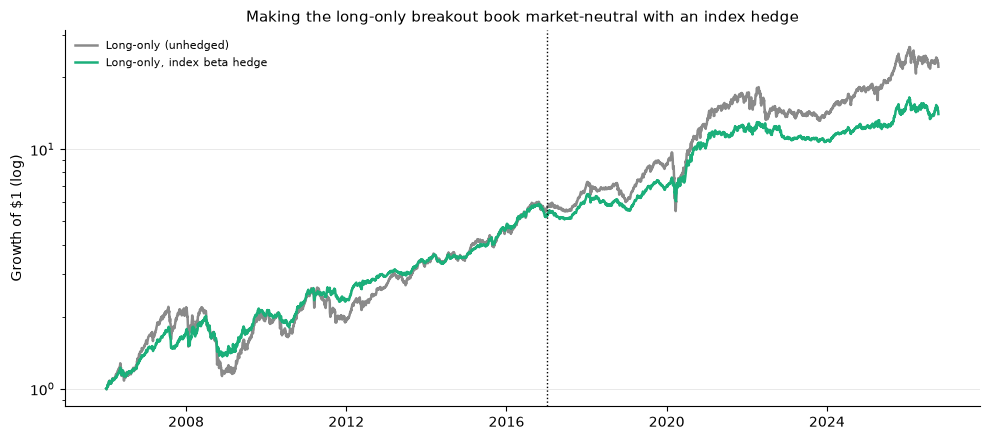

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for (name, sr), c in zip(hedge_bts.items(), [GREY, AQUA]):
    ax.plot((1 + sr.loc["2006":]).cumprod(), color=c, lw=1.8, label=name)
ax.axvline(pd.Timestamp("2017-01-01"), color="k", ls=":", lw=1)
ax.set_yscale("log")
ax.set_ylabel("Growth of $1 (log)")
ax.set_title("Making the long-only breakout book market-neutral with an index hedge", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "beta_hedge.png", dpi=130)
plt.show()

* The hedge does what the regression promises: beta drops from 0.7–0.9 to about 0, volatility falls from 19% to 13%, and the alpha is kept.
* Out-of-sample the hedged book has the same Sharpe as the unhedged one (0.80 against 0.82) with **less than half the drawdown** (−20% against −43%), and it needs only index futures to short.
* The hedge is large-cap while many of the longs are smaller companies. In 2008 the longs fell more than the index hedge offset, so the in-sample drawdown is still −32%.

### 14b. Residual breakouts (signal-level beta removal)

* For each stock, regress its daily returns on the All Ords over a rolling 252-day window to get $\beta_{i,t}$ (using data up to yesterday only).
* Residual return: $\varepsilon_{i,t} = r_{i,t} - \beta_{i,t-1}\, r^{index}_t$. Cumulating the residuals gives a "residual price".
* Apply the same breakout rules to the residual price. There is no residual high or low, so channels use closing values, and the plain-price version is re-run on closes too so the comparison is like for like.

In [27]:
R, mret = df["ret"], axjo.reindex(df["ret"].index)
W = 252
mean_m = mret.rolling(W, min_periods=126).mean()
cov_im = R.mul(mret, axis=0).rolling(W, min_periods=126).mean() - R.rolling(W, min_periods=126).mean().mul(mean_m, axis=0)
beta_i = cov_im.div(mret.rolling(W, min_periods=126).var(), axis=0).shift(1)
resid_px = (1 + (R - beta_i.mul(mret, axis=0)).fillna(0)).cumprod().where(df["adj"].notna())


def donchian_long_close(px, n, m, member):
    up_n = px.rolling(n, min_periods=n).max().shift(1)
    lo_m = px.rolling(m, min_periods=m).min().shift(1)
    st = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
    return st.mask((px < lo_m) | ~member, 0.0).mask((px > up_n) & member, 1.0).ffill().fillna(0.0)


resid_rows = {}
for label, px in [("price breakout (close-based)", df["adj"]), ("residual breakout", resid_px)]:
    net = backtest_drift(donchian_long_close(px, N, M, df["member"]), df)["net"]
    for per, sl in PERIODS:
        resid_rows[(label, per)] = stats(net.loc[sl], ew)
resid_table = pd.DataFrame(resid_rows).T
resid_table.to_csv(RESULTS / "12b_residual_breakout.csv")
resid_table[["sharpe", "max_dd", "alpha", "alpha_t"]]

sharpe  max_dd  alpha  alpha_t
price breakout (close-based) IS    0.978  -0.492  0.132    4.339
                             OOS   0.825  -0.425  0.080    3.220
residual breakout            IS    0.949  -0.525  0.124    4.665
                             OOS   0.818  -0.431  0.077    3.097

**Residual breakouts do not help.** They are slightly worse than plain price breakouts in both periods (Sharpe 0.95 against 0.98 in-sample, 0.82 against 0.83 out-of-sample).

**Verdict on removing beta**
* **When measuring performance: yes.** That is the alpha regression, used throughout.
* **When building the portfolio: worthwhile.** The index hedge keeps the alpha and halves the drawdown.
* **When building the signal: not worthwhile here.**

## 15. Conclusions

In [28]:
summary = final.loc[(slice(None), ["IS", "OOS"]), ["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta_aord", "turnover"]]
summary.style.format({"ann_ret": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}", "alpha": "{:.1%}",
                      "alpha_t": "{:.1f}", "beta_aord": "{:.2f}", "turnover": "{:.2%}"}, na_rep="")

,,ann_ret,ann_vol,sharpe,max_dd,alpha,alpha_t,beta_aord,turnover
strategy,period,,,,,,,,
Breakout long-only,IS,17.4%,18.4%,0.95,-48.6%,12.7%,4.4,0.72,3.06%
Benchmark: EW ASX 500,IS,5.4%,18.3%,0.30,-68.0%,,,,
Benchmark: All Ords,IS,3.3%,17.5%,0.19,-54.6%,,,,
Breakout long-only,OOS,15.7%,19.2%,0.82,-43.1%,7.8%,3.2,0.92,2.92%
Benchmark: EW ASX 500,OOS,9.2%,20.3%,0.45,-45.3%,,,,
Benchmark: All Ords,OOS,5.5%,14.6%,0.37,-37.1%,,,,


**Findings**
1. **A long-only breakout book works on the ASX 500.** Entering on a 200-day high and exiting on a 50-day low, chosen on 2006–2016 only, earns 15.7% a year out-of-sample after IBKR costs (Sharpe 0.82), with alpha of 7.8% a year over the equal-weight ASX 500 (t = 3.2).
2. **Horizon decides the sign.** Breakouts of 20 days or less reverse; breakouts of 150–250 days persist. This is the brief's "short horizon → reversal, long horizon → momentum" pattern.
3. **Execution:** trade the day after the breakout, not on the breakout close.
4. **Costs:** the bid-ask spread costs about three times IBKR's commission. Together they take 2.8% a year and the alpha survives, even with the spread doubled.
5. **Account size:** IBKR's A$6 minimum per order makes the strategy unprofitable on A$1m as it is built, because it sends about 115 small orders a day. It needs about A$10m or more, or less frequent trimming.
6. **Significance:** the book beats random baskets, random timing and its benchmark out-of-sample. After correcting for the in-sample search the in-sample result is only borderline, so the once-only out-of-sample test is what establishes the edge.
7. **Removing beta:** hedging with index futures keeps the alpha and cuts the out-of-sample drawdown from −43% to −20%.

**Caveats**
* **Survivorship:** only today's listed companies are included. Alpha is measured against an equal-weight universe with the same bias, but a delisted-inclusive database is needed for a clean test.
* **No value-weighted version.** The data has no reliable history of market capitalisation, so every result here is for equal-weighted entries (see the README).
* **Spread assumption:** half of one tick per trade. Thin small caps often quote wider than one tick, and the "2 × half-spread" row is the guide to that.
* **Capacity vs minimum fee:** the names held are thin, yet the minimum fee favours a large account (sections 8 and 11).
* **Long-only means equity risk.** The unhedged book lost 44% in 2008.
* **Data:** Yahoo errors were filtered (notebook 01), but some may remain.

**Next steps:** survivorship-free data; market-cap history, to test value weighting; batching the small trimming orders so a small account can run the book; per-name and liquidity caps.